[![../img/pythonista.png](../img/pythonista.png)](https://www.pythonista.io)

# Estadística descriptiva, forma de la distribución y valores atípicos.

**py401 · EDA Práctico** · Pythonista® · Instructor: José Luis Chiquete
**Miércoles 21 de octubre de 2026 · 6:30 a 8:30 pm (CDMX)** · Módulo II: *Describir y comparar*

> 🔑 **Versión con soluciones.** Solo para el instructor o para revisión posterior.

En esta sesión se describirán distribuciones con medidas clásicas y robustas (media, mediana, desviación estándar, IQR y MAD), se analizará su forma (asimetría, curtosis y multimodalidad) con histogramas, KDE, ECDF y diagramas de caja, y se detectarán valores atípicos con la regla del IQR y el puntaje *z* robusto, usando `penguins_limpio`.

## 🎯 Objetivo de la sesión.

**Describir distribuciones con medidas robustas y detectar valores atípicos sin eliminarlos por reflejo.**

Al terminar podrás:
1. Calcular e interpretar media, mediana, desviación estándar, IQR y MAD, y saber cuáles son robustas.
2. Describir la forma de una distribución (asimetría, curtosis, multimodalidad) y elegir la gráfica adecuada: histograma, KDE, ECDF o diagrama de caja.
3. Detectar valores atípicos con la regla del IQR, el puntaje *z* y el puntaje *z* robusto, y decidir si son errores o valores reales.
4. Aplicar una transformación logarítmica y explicar su efecto.

## 🗺️ Agenda (120 min).

| Min | Bloque |
|---|---|
| 10 | Repaso: `penguins_limpio` |
| 25 | 1. Tendencia central y dispersión |
| 25 | 2. Forma de la distribución |
| 25 | 3. Valores atípicos |
| 15 | 4. Transformaciones (log) |
| 20 | 5. Ejercicio integrador y cierre |

🟢 = ejercicio básico · 🔴 = reto opcional

### Preparación del entorno.

* La siguiente celda importará las bibliotecas, incluido el módulo `stats` de *SciPy*, y definirá `DATA` y la semilla `rng`.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA = next(os.path.join(p, "data") for p in (os.curdir, os.pardir)
            if os.path.isfile(os.path.join(p, "data", "penguins.csv")))
pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")
rng = np.random.default_rng(401)
from scipy import stats

warnings.filterwarnings("ignore", message="vert: bool was deprecated")

**Nota:** el filtro de advertencias oculta solo un aviso interno de *Seaborn* 0.13 con *Matplotlib* 3.11 al dibujar diagramas de caja (`vert: bool was deprecated`). No afecta los resultados.

---
## 0. Repaso: `penguins_limpio` (10 min).

En la sesión 2 se generó `data/penguins_limpio.csv`: `sex` homologado a `Male`/`Female`, sin las 2 filas que no tenían medidas y con `sex` faltante sin imputar. Si el archivo no existe (por ejemplo, porque no se ejecutó el *notebook* 02), se regenera con las mismas decisiones.

* La siguiente celda leerá `penguins_limpio.csv` o lo regenerará desde `penguins.csv` si no existe.

In [2]:
ruta_limpio = os.path.join(DATA, "penguins_limpio.csv")
medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
if not os.path.isfile(ruta_limpio):
    (
        pd.read_csv(os.path.join(DATA, "penguins.csv"))
        .assign(sex=lambda d: d["sex"].str.title())
        .dropna(subset=medidas, how="all")
        .to_csv(ruta_limpio, index=False)
    )
pinguinos = pd.read_csv(ruta_limpio).astype({"species": "category", "island": "category", "sex": "category"})
pinguinos.shape

(342, 7)

* La siguiente celda mostrará los tipos y los faltantes que quedan.

In [3]:
pd.DataFrame({"dtype": pinguinos.dtypes.astype(str), "faltantes": pinguinos.isna().sum()})

,dtype,faltantes
species,category,0
island,category,0
bill_length_mm,float64,0
bill_depth_mm,float64,0
flipper_length_mm,int64,0
body_mass_g,int64,0
sex,category,9


---
## 1. Tendencia central y dispersión (25 min).

| Medida | Qué resume | ¿Robusta? | En código |
|---|---|---|---|
| Media | Centro de gravedad | No: un solo valor extremo la arrastra | `s.mean()` |
| Mediana | Valor que deja la mitad de los datos a cada lado | Sí | `s.median()` |
| Desviación estándar | Distancia típica a la media | No | `s.std()` (con `ddof=1`) |
| IQR (rango intercuartílico) | Ancho del 50% central: Q3 − Q1 | Sí | `stats.iqr(s)` |
| MAD (desviación absoluta mediana) | Mediana de \|x − mediana\| | Sí | `stats.median_abs_deviation(s, scale="normal")` |

Una medida es **robusta** si no cambia mucho cuando una pequeña parte de los datos es extrema o errónea. Con `scale="normal"`, la MAD se multiplica por 1.4826 para que sea comparable con la desviación estándar cuando los datos son normales.

* La siguiente celda extraerá la masa de los Adelie.

In [4]:
masa_adelie = pinguinos.loc[pinguinos["species"] == "Adelie", "body_mass_g"]
masa_adelie.describe()

count     151.000000
mean     3700.662252
std       458.566126
min      2850.000000
25%      3350.000000
50%      3700.000000
75%      4000.000000
max      4775.000000
Name: body_mass_g, dtype: float64

* La siguiente celda calculará las cinco medidas para la masa de los Adelie.

In [5]:
pd.Series({
    "media": masa_adelie.mean(),
    "mediana": masa_adelie.median(),
    "desv_est": masa_adelie.std(),
    "iqr": stats.iqr(masa_adelie),
    "mad": stats.median_abs_deviation(masa_adelie, scale="normal"),
}).round(1)

media       3700.7
mediana     3700.0
desv_est     458.6
iqr          650.0
mad          444.8
dtype: float64

**Ejemplo:** se simulará un error de captura: alguien escribe 37,500 g en lugar de 3,750 g. Se compararán las medidas con y sin ese único valor.

* La siguiente celda agregará el valor erróneo y comparará las medidas.

In [6]:
con_error = pd.concat([masa_adelie, pd.Series([37500])], ignore_index=True)

def medidas_basicas(serie):
    return pd.Series({
        "media": serie.mean(),
        "mediana": serie.median(),
        "desv_est": serie.std(),
        "iqr": stats.iqr(serie),
        "mad": stats.median_abs_deviation(serie, scale="normal"),
    })

pd.DataFrame({"original": medidas_basicas(masa_adelie), "con un error": medidas_basicas(con_error)}).round(1)

,original,con un error
media,3700.7,3923.0
mediana,3700.0,3700.0
desv_est,458.6,2779.3
iqr,650.0,650.0
mad,444.8,444.8


Un solo valor erróneo entre 152 sube la media en más de 200 g (de 3,701 a 3,923 g) y multiplica por seis la desviación estándar (de 459 a 2,779 g), mientras que la mediana, el IQR y la MAD no se mueven. Por eso, ante datos sospechosos, conviene reportar **mediana e IQR** junto con media y desviación estándar.

### 🟢 Ejercicio 1 · Una función de resumen.

Escribe `resumen(serie)` que devuelva una `Series` con `n` (no nulos), `media`, `mediana`, `desv_est`, `iqr` y `mad` (con `scale="normal"`), ignorando los faltantes. Aplícala a `body_mass_g` y a `flipper_length_mm` de todos los pingüinos y muestra ambos resultados en un *dataframe*.

* La siguiente celda muestra una solución posible.

In [7]:
def resumen(serie):
    serie = serie.dropna()
    return pd.Series({
        "n": serie.size,
        "media": serie.mean(),
        "mediana": serie.median(),
        "desv_est": serie.std(),
        "iqr": stats.iqr(serie),
        "mad": stats.median_abs_deviation(serie, scale="normal"),
    })

pd.DataFrame({c: resumen(pinguinos[c]) for c in ["body_mass_g", "flipper_length_mm"]}).round(1)

,body_mass_g,flipper_length_mm
n,342.0,342.0
media,4201.8,200.9
mediana,4050.0,197.0
desv_est,802.0,14.1
iqr,1200.0,23.0
mad,889.6,16.3


### 🟢 Ejercicio 2 · Descripción por especie.

Describe `body_mass_g` y `flipper_length_mm` **por especie** con las mismas medidas (pista: `groupby("species")[columna].apply(resumen).unstack()`, o `agg` con una lista de funciones). Compara con el resumen global del ejercicio 1: ¿qué medida global describe mal a **todas** las especies?

* La siguiente celda muestra una solución posible.

In [8]:
por_especie = {c: pinguinos.groupby("species")[c].apply(resumen).unstack().round(1)
               for c in ["body_mass_g", "flipper_length_mm"]}
pd.concat(por_especie, axis=1)

body_mass_g                                         \
                    n   media mediana desv_est    iqr    mad   
species                                                        
Adelie          151.0  3700.7  3700.0    458.6  650.0  444.8   
Chinstrap        68.0  3733.1  3700.0    384.3  462.5  370.7   
Gentoo          123.0  5076.0  5000.0    504.1  800.0  556.0   

          flipper_length_mm                                     
                          n  media mediana desv_est   iqr  mad  
species                                                         
Adelie                151.0  190.0   190.0      6.5   9.0  7.4  
Chinstrap              68.0  195.8   196.0      7.1  10.0  7.4  
Gentoo                123.0  217.2   216.0      6.5   9.0  5.9

**✅ Respuesta sugerida:**

La media global de la masa (4,202 g) y su desviación estándar (802 g) no describen a **ninguna** especie: Adelie y Chinstrap rondan los 3,700 g y Gentoo los 5,076 g, y dentro de cada especie la desviación es de 384 a 504 g. La dispersión global es grande porque mezcla grupos con centros distintos. Lo mismo pasa con la aleta: 201 mm global contra 190, 196 y 217 mm por especie.

### 🔴 Reto 1 · Punto de quiebre.

Toma la masa de los Gentoo y reemplaza una proporción creciente de valores (0%, 5%, 10%, …, 45%) por un valor absurdo (60,000 g). Para cada proporción calcula media, mediana, desviación estándar y MAD, y grafica cómo cambian. ¿A partir de qué proporción deja de servir la mediana? (El **punto de quiebre** de la media es 0%; el de la mediana, 50%.)

* La siguiente celda muestra una solución posible.

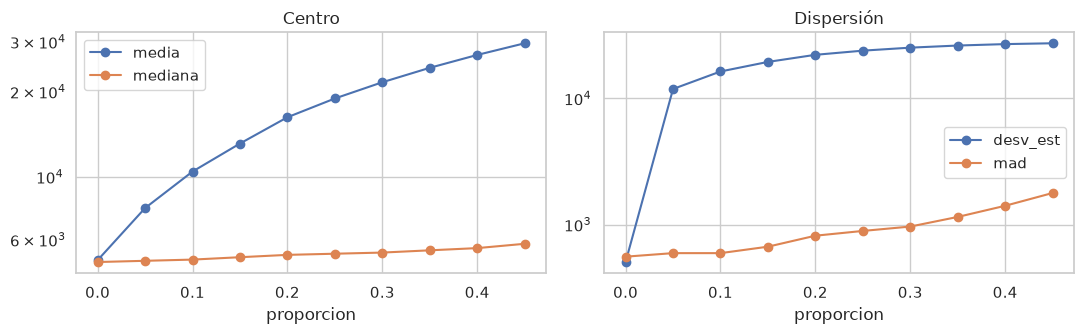

,media,mediana,desv_est,mad
proporcion,,,,
0.00,5076.0,5000.0,504.0,556.0
0.05,7757.0,5050.0,11889.0,593.0
0.10,10441.0,5100.0,16368.0,593.0
0.15,13116.0,5200.0,19496.0,667.0
0.20,16244.0,5300.0,22195.0,815.0
0.25,18925.0,5350.0,23944.0,890.0
0.30,21597.0,5400.0,25295.0,964.0
0.35,24289.0,5500.0,26291.0,1149.0
0.40,26973.0,5600.0,26988.0,1408.0


In [9]:
masa_gentoo = pinguinos.loc[pinguinos["species"] == "Gentoo", "body_mass_g"].to_numpy(dtype=float)
filas = []
for proporcion in np.arange(0, 0.50, 0.05):
    contaminada = masa_gentoo.copy()
    n_malos = int(round(proporcion * contaminada.size))
    contaminada[:n_malos] = 60000  # sin usar rng, para no alterar las simulaciones posteriores
    filas.append({"proporcion": proporcion, "media": contaminada.mean(), "mediana": np.median(contaminada),
                  "desv_est": contaminada.std(ddof=1), "mad": stats.median_abs_deviation(contaminada, scale="normal")})
quiebre = pd.DataFrame(filas).set_index("proporcion")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
quiebre[["media", "mediana"]].plot(ax=axes[0], marker="o", logy=True, title="Centro")
quiebre[["desv_est", "mad"]].plot(ax=axes[1], marker="o", logy=True, title="Dispersión")
plt.tight_layout()
plt.show()
quiebre.round(0)

**✅ Respuesta sugerida:**

Con solo 5% de valores absurdos la media pasa de 5,076 a 7,757 g y la desviación estándar de 504 a casi 11,900 g: dejan de servir de inmediato. La mediana sube despacio (de 5,000 a 5,800 g con 45% contaminado) y la MAD crece de forma moderada (de 556 a 1,779 g). La mediana sigue siendo útil hasta acercarse a 50%; a partir de ahí, la mitad de los datos son absurdos y ya no puede distinguirlos.

---
## 2. Forma de la distribución (25 min).

* **Asimetría** (*skewness*): positiva si la cola larga está a la derecha (media > mediana), negativa si está a la izquierda. Cerca de 0 indica simetría.
* **Curtosis** (en exceso): compara el peso de las colas con una normal (0). Positiva = colas más pesadas, más valores extremos.
* **Multimodalidad:** más de un pico. Suele indicar que se mezclan **grupos distintos**.

`pandas` calcula ambas con `s.skew()` y `s.kurt()` (versiones corregidas por sesgo); *SciPy* ofrece `stats.skew` y `stats.kurtosis`.

* La siguiente celda calculará la asimetría y la curtosis de las cuatro medidas.

In [10]:
pd.DataFrame({"asimetria": pinguinos[medidas].skew(), "curtosis": pinguinos[medidas].kurt()}).round(2)

,asimetria,curtosis
bill_length_mm,0.05,-0.88
bill_depth_mm,-0.14,-0.91
flipper_length_mm,0.35,-0.98
body_mass_g,0.47,-0.72


### 2.1 Cuatro gráficas para una variable.

| Gráfica | Fortaleza | Cuidado |
|---|---|---|
| Histograma | Intuitivo; muestra picos y huecos | Depende del número de *bins* |
| KDE (densidad suavizada) | Curva continua; fácil de superponer por grupo | Depende del ancho de banda; puede "inventar" valores fuera del rango |
| ECDF (distribución acumulada empírica) | Sin parámetros; se leen percentiles directamente | Menos intuitiva al principio |
| Diagrama de caja | Mediana, IQR y atípicos de un vistazo; compara muchos grupos | Oculta la multimodalidad |

* La siguiente celda dibujará las cuatro gráficas de `flipper_length_mm` para todos los pingüinos.

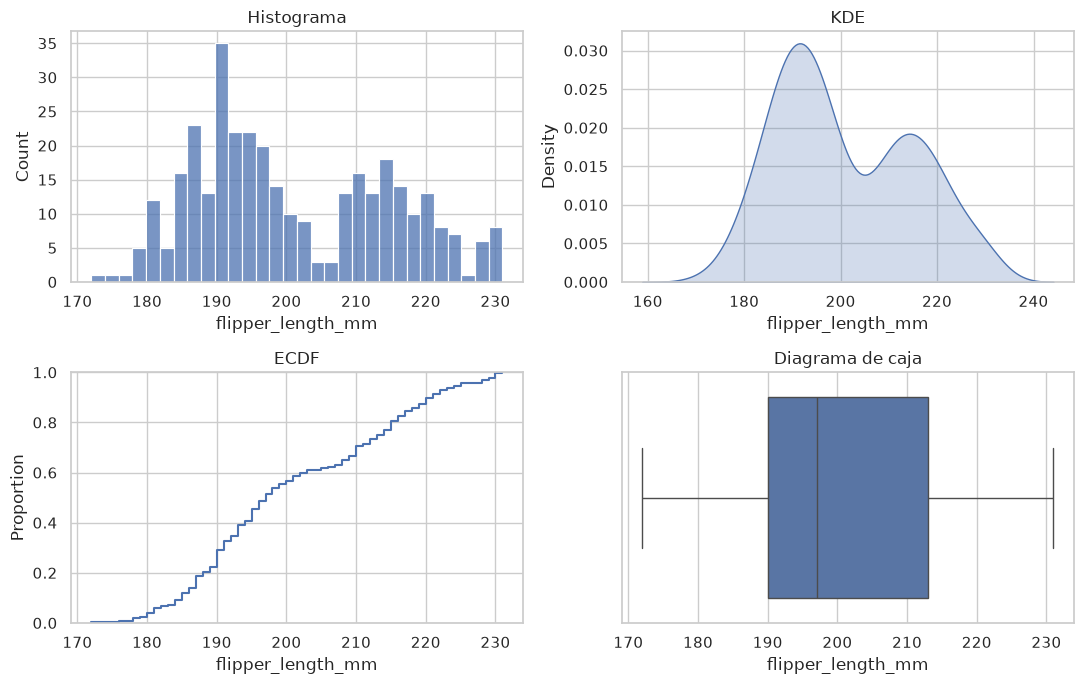

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
sns.histplot(pinguinos, x="flipper_length_mm", bins=30, ax=axes[0, 0]).set(title="Histograma")
sns.kdeplot(pinguinos, x="flipper_length_mm", fill=True, ax=axes[0, 1]).set(title="KDE")
sns.ecdfplot(pinguinos, x="flipper_length_mm", ax=axes[1, 0]).set(title="ECDF")
sns.boxplot(pinguinos, x="flipper_length_mm", ax=axes[1, 1]).set(title="Diagrama de caja")
plt.tight_layout()
plt.show()

El histograma y la KDE muestran **dos picos**; el diagrama de caja los esconde por completo. Por eso nunca conviene describir una variable solo con un diagrama de caja.

### 🟢 Ejercicio 3 · ¿Por qué la distribución global es bimodal?

Grafica la distribución de `flipper_length_mm` y de `body_mass_g` **separada por especie** (pista: `sns.histplot(..., hue="species")` o `sns.kdeplot(..., hue="species")`). Explica por qué la distribución global se ve bimodal y qué cambia al separar por especie.

* La siguiente celda muestra una solución posible.

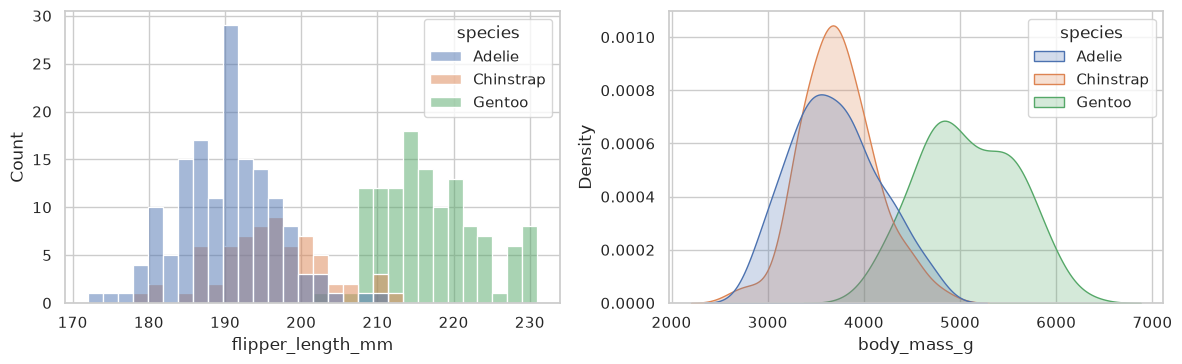

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(pinguinos, x="flipper_length_mm", hue="species", bins=30, ax=axes[0])
sns.kdeplot(pinguinos, x="body_mass_g", hue="species", fill=True, common_norm=False, ax=axes[1])
plt.tight_layout()
plt.show()

**✅ Respuesta sugerida:**

Los Gentoo forman un pico propio (aletas de unos 217 mm y masas de unos 5,000 g), mientras que Adelie y Chinstrap se traslapan en otro (aletas de 190 a 196 mm y masas de unos 3,700 g). La distribución global es la **mezcla** de esos grupos. Al separar por especie, cada distribución es unimodal y aproximadamente simétrica.

### 🟢 Ejercicio 4 · Forma por especie.

1. Calcula la asimetría y la curtosis de `body_mass_g` **por especie** y compara la media con la mediana en cada una.
2. Dibuja la ECDF de `body_mass_g` por especie. Con la gráfica, estima qué proporción de Gentoo pesa menos de 5,000 g y compruébalo con código.

* La siguiente celda muestra una solución posible.

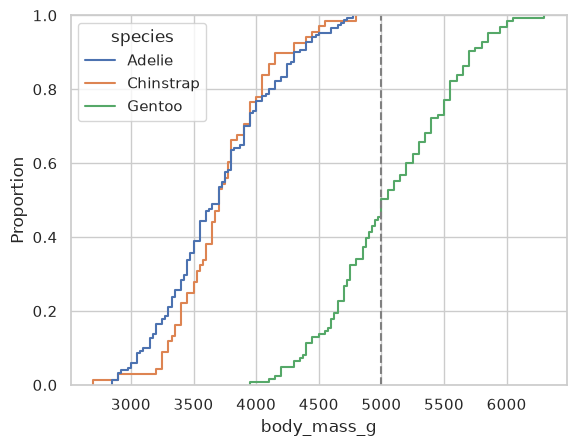

(           asimetria  curtosis    media  mediana
 species                                         
 Adelie          0.29     -0.57  3700.66   3700.0
 Chinstrap       0.25      0.59  3733.09   3700.0
 Gentoo          0.07     -0.72  5076.02   5000.0,
 0.455)

In [13]:
forma = pinguinos.groupby("species")["body_mass_g"].agg(
    asimetria="skew",
    curtosis=lambda s: s.kurt(),
    media="mean",
    mediana="median",
).round(2)
gentoo_menos_5000 = (pinguinos.loc[pinguinos["species"] == "Gentoo", "body_mass_g"] < 5000).mean()
sns.ecdfplot(pinguinos, x="body_mass_g", hue="species")
plt.axvline(5000, color="gray", linestyle="--")
plt.show()
forma, round(float(gentoo_menos_5000), 3)

**✅ Respuesta sugerida:**

En las tres especies la asimetría es pequeña (0.07 a 0.29) y la media casi coincide con la mediana (diferencias menores a 80 g), así que media y desviación estándar son buenas descripciones dentro de cada especie. La curtosis está cerca de 0; Chinstrap tiene colas algo más pesadas (0.59). En la ECDF se lee que cerca de 45% de los Gentoo pesa menos de 5,000 g (el cálculo da 45.5%).

### 🔴 Reto 2 · ¿Cuántos picos? Depende de cómo se mire.

Dibuja la KDE global de `flipper_length_mm` con `bw_adjust` igual a 0.2, 1 y 3, y el histograma con 5, 20 y 60 *bins*. ¿Cuándo aparecen o desaparecen picos? ¿Qué recomendarías para no engañarte?

* La siguiente celda muestra una solución posible.

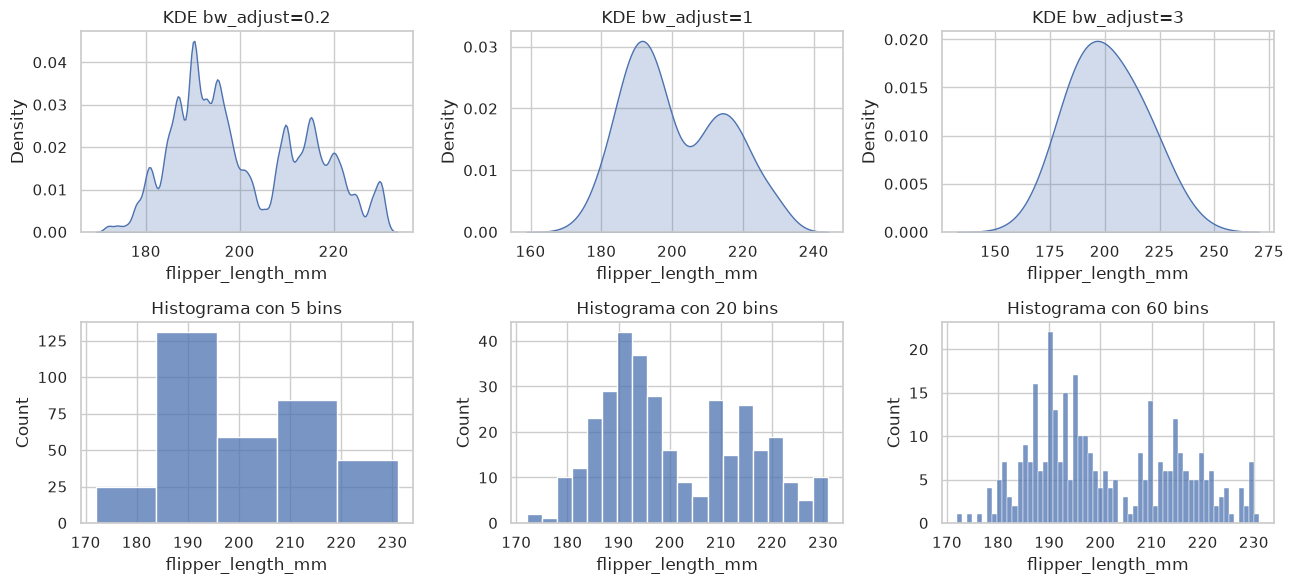

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, ajuste in zip(axes[0], [0.2, 1, 3]):
    sns.kdeplot(pinguinos, x="flipper_length_mm", bw_adjust=ajuste, fill=True, ax=ax).set(title=f"KDE bw_adjust={ajuste}")
for ax, n_bins in zip(axes[1], [5, 20, 60]):
    sns.histplot(pinguinos, x="flipper_length_mm", bins=n_bins, ax=ax).set(title=f"Histograma con {n_bins} bins")
plt.tight_layout()
plt.show()

**✅ Respuesta sugerida:**

Con `bw_adjust=0.2` o 60 *bins* aparecen picos espurios (ruido); con `bw_adjust=3` o 5 *bins* la bimodalidad casi desaparece. Conviene probar varios valores, complementar con la ECDF (que no tiene parámetros) y, sobre todo, buscar la explicación de los picos en otra variable (aquí, la especie).

---
## 3. Valores atípicos (25 min).

Un valor atípico (*outlier*) es una observación muy alejada del resto. **No es sinónimo de error**: puede ser un error de captura, un caso real extremo o la señal de que se mezclan grupos.

| Regla | Atípico si… | Ventaja | Problema |
|---|---|---|---|
| IQR (Tukey) | x < Q1 − 1.5·IQR o x > Q3 + 1.5·IQR | Robusta; es la del diagrama de caja | Marca muchos en distribuciones asimétricas |
| Puntaje *z* | \|x − media\| / desv_est > 3 | Simple | La media y la desviación estándar se contaminan con los propios atípicos (*enmascaramiento*) |
| *z* robusto | \|x − mediana\| / MAD > 3.5 | Robusta | Supone una distribución aproximadamente simétrica |

El umbral de 3.5 para el *z* robusto es el que recomiendan Iglewicz y Hoaglin (1993).

* La siguiente celda definirá las tres reglas como funciones que devuelven una máscara booleana.

In [15]:
def atipicos_iqr(serie, k=1.5):
    q1, q3 = serie.quantile([0.25, 0.75])
    return (serie < q1 - k * (q3 - q1)) | (serie > q3 + k * (q3 - q1))

def atipicos_z(serie, umbral=3):
    return ((serie - serie.mean()) / serie.std()).abs() > umbral

def z_robusto(serie):
    return (serie - serie.median()) / stats.median_abs_deviation(serie, scale="normal", nan_policy="omit")

def atipicos_z_robusto(serie, umbral=3.5):
    return z_robusto(serie).abs() > umbral

**Ejemplo:** se simularán 200 mediciones normales (media 200, desviación 10) más 25 errores de captura cercanos a 300, para ver qué detecta cada regla.

* La siguiente celda creará la muestra contaminada y contará cuántos atípicos marca cada regla.

In [16]:
simulada = pd.Series(np.concatenate([rng.normal(200, 10, size=200), rng.normal(300, 3, size=25)]))
pd.Series({
    "IQR": atipicos_iqr(simulada).sum(),
    "z > 3": atipicos_z(simulada).sum(),
    "z robusto > 3.5": atipicos_z_robusto(simulada).sum(),
})

IQR                26
z > 3               0
z robusto > 3.5    25
dtype: int64

Las reglas robustas encuentran los 25 errores (la del IQR puede marcar, además, algún valor legítimo extremo); el puntaje *z* clásico no encuentra **ninguno**. Es el efecto de **enmascaramiento**.

* La siguiente celda mostrará por qué falla el puntaje *z*: los errores inflan la media y la desviación estándar.

In [17]:
pd.DataFrame({"limpia": medidas_basicas(simulada[:200]), "contaminada": medidas_basicas(simulada)}).round(1)

,limpia,contaminada
media,198.8,210.0
mediana,199.0,201.2
desv_est,9.3,33.1
iqr,12.3,14.4
mad,9.1,10.7


### ¿Error o valor real?

Antes de tocar un atípico conviene preguntarse:
1. ¿Es **imposible** (masa negativa, aleta de 2 m)? → error: corregir si la causa es clara o pasar a `NaN` (sesión 2).
2. ¿Es **plausible** pero extremo? → se conserva y se reporta; se puede analizar con y sin él.
3. ¿Es atípico **solo en el conjunto global** y normal dentro de su grupo? → no es atípico: se están mezclando grupos.
4. ¿Hay forma de **verificar** con la fuente? → esa es la mejor opción.

**Advertencia:** borrar atípicos "por reflejo" para que los datos se vean normales es una forma de manipulación. Toda exclusión se documenta y se justifica.

### 🟢 Ejercicio 5 · Atípicos en `penguins`.

Para `body_mass_g` y `flipper_length_mm`:
1. Marca los atípicos con la regla del IQR y con el *z* robusto, **globalmente** y **dentro de cada especie** (pista: `pinguinos.groupby("species")[columna].transform(atipicos_iqr)`).
2. Compara las listas: ¿qué filas marca cada regla? ¿Coinciden?

* La siguiente celda muestra una solución posible.

In [18]:
marcas = pd.DataFrame(index=pinguinos.index)
for columna in ["body_mass_g", "flipper_length_mm"]:
    marcas[f"{columna}_iqr_global"] = atipicos_iqr(pinguinos[columna])
    marcas[f"{columna}_zr_global"] = atipicos_z_robusto(pinguinos[columna])
    por_especie = pinguinos.groupby("species")[columna]
    marcas[f"{columna}_iqr_especie"] = por_especie.transform(atipicos_iqr)
    marcas[f"{columna}_zr_especie"] = por_especie.transform(atipicos_z_robusto)
marcas.sum()

body_mass_g_iqr_global           0
body_mass_g_zr_global            0
body_mass_g_iqr_especie          2
body_mass_g_zr_especie           0
flipper_length_mm_iqr_global     0
flipper_length_mm_zr_global      0
flipper_length_mm_iqr_especie    2
flipper_length_mm_zr_especie     0
dtype: int64

* La siguiente celda mostrará las filas marcadas por al menos una regla (requiere `marcas`).

In [19]:
if "marcas" in globals():
    marcadas = marcas.any(axis=1)
    columnas_mostrar = ["species", "sex", "body_mass_g", "flipper_length_mm"]
    resultado = pinguinos.loc[marcadas, columnas_mostrar].join(marcas.loc[marcadas].astype(int).T.loc[lambda d: d.any(axis=1)].T)
else:
    resultado = None
resultado

,species,sex,body_mass_g,flipper_length_mm,body_mass_g_iqr_especie,flipper_length_mm_iqr_especie
27,Adelie,Female,3150,172,0,1
128,Adelie,Male,4000,210,0,1
188,Chinstrap,Male,4800,210,1,0
189,Chinstrap,Female,2700,192,1,0


**✅ Respuesta sugerida:**

En el conjunto **global** ninguna regla marca atípicos: al mezclar especies la dispersión es tan grande que nada queda lejos. **Dentro de cada especie**, la regla del IQR marca 2 masas (un macho Chinstrap de 4,800 g y una hembra Chinstrap de 2,700 g) y 2 aletas (dos Adelie, de 172 y 210 mm); el *z* robusto con umbral 3.5 no marca ninguno (el mayor es 2.97). Las listas no coinciden porque la regla del IQR es más sensible (marca más valores): para datos normales, 1.5·IQR equivale a unos 2.7 desviaciones estándar, contra 3.5 del *z* robusto.

### 🟢 Ejercicio 6 · ¿Error o valor real?

Con base en la tabla anterior y en lo que sabes de los pingüinos, decide para cada atípico encontrado si lo tratarías como error o como valor real, y qué harías con él en el análisis.

**✅ Respuesta sugerida:**

Ninguno es imposible: todos están dentro de los rangos conocidos para su especie. La hembra Chinstrap de 2,700 g es la más ligera del *dataset*, pero es plausible (una hembra pequeña o en mal estado). Se tratan como **valores reales**: se conservan, se mencionan en el informe y, si un análisis resulta sensible a ellos, se reporta con y sin esos casos. Si hubiera acceso a las notas de campo, convendría verificarlos.

### 🔴 Reto 3 · Atípicos que solo existen dentro del grupo.

Encuentra los pingüinos cuyo `bill_length_mm` es atípico **dentro de su especie** según el *z* robusto, pero **no** lo es en el conjunto global (o al revés). Grafícalos resaltados sobre un diagrama de dispersión `bill_length_mm` vs. `bill_depth_mm` coloreado por especie. ¿Por qué ocurre?

* La siguiente celda muestra una solución posible.

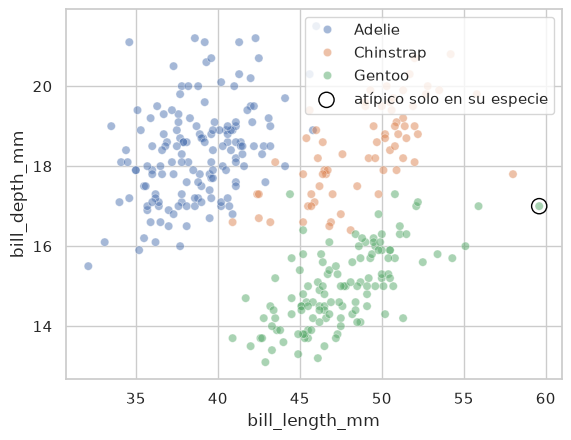

,species,sex,bill_length_mm,bill_depth_mm
252,Gentoo,Male,59.6,17.0


In [20]:
global_zr = atipicos_z_robusto(pinguinos["bill_length_mm"])
especie_zr = pinguinos.groupby("species")["bill_length_mm"].transform(atipicos_z_robusto)
solo_en_especie = especie_zr & ~global_zr
solo_global = global_zr & ~especie_zr
ax = sns.scatterplot(pinguinos, x="bill_length_mm", y="bill_depth_mm", hue="species", alpha=0.5)
ax.scatter(pinguinos.loc[solo_en_especie, "bill_length_mm"], pinguinos.loc[solo_en_especie, "bill_depth_mm"],
           s=120, facecolors="none", edgecolors="black", label="atípico solo en su especie")
ax.legend()
plt.show()
pinguinos.loc[solo_en_especie | solo_global, ["species", "sex", "bill_length_mm", "bill_depth_mm"]]

**✅ Respuesta sugerida:**

Un macho Gentoo con pico de 59.6 mm (el más largo del *dataset*) es atípico dentro de su especie (*z* robusto ≈ 3.95), pero no en el conjunto global, porque la distribución global de `bill_length_mm` es ancha al incluir a los Chinstrap y Gentoo de pico largo. Mezclar grupos **enmascara** atípicos: por eso se buscan dentro de cada grupo.

---
## 4. Transformaciones (15 min).

Muchas variables positivas (ingresos, precios, tiempos, tamaños de población) tienen **asimetría positiva** fuerte: la mayoría de los valores son pequeños y unos pocos son enormes. El **logaritmo** comprime la cola derecha:

* Convierte diferencias multiplicativas en aditivas (×10 pasa a ser +1 en `log10`).
* Reduce la asimetría y la influencia de los valores grandes.
* Solo se aplica a valores positivos; con ceros se usa `np.log1p(x)` = log(1 + x).
* Al volver a la escala original, la media de los logaritmos corresponde a la **media geométrica**, no a la media aritmética.

`penguins` es casi simétrico, así que se simularán ingresos mensuales con una distribución lognormal.

* La siguiente celda simulará 1,000 ingresos mensuales (en pesos) y su logaritmo base 10.

In [21]:
ingresos = pd.Series(rng.lognormal(mean=np.log(15000), sigma=0.8, size=1000), name="ingreso")
log_ingresos = np.log10(ingresos)
pd.DataFrame({
    "ingreso": [ingresos.skew(), ingresos.mean(), ingresos.median(), atipicos_iqr(ingresos).sum()],
    "log10(ingreso)": [log_ingresos.skew(), log_ingresos.mean(), log_ingresos.median(), atipicos_iqr(log_ingresos).sum()],
}, index=["asimetria", "media", "mediana", "atipicos IQR"]).round(2)

,ingreso,log10(ingreso)
asimetria,2.31,-0.04
media,20065.53,4.16
mediana,14918.90,4.17
atipicos IQR,63.00,4.00


* La siguiente celda comparará ambas distribuciones gráficamente.

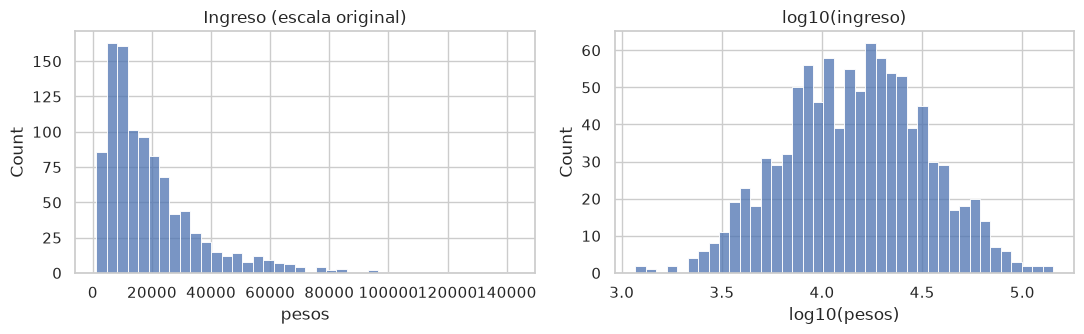

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(ingresos, bins=40, ax=axes[0]).set(title="Ingreso (escala original)", xlabel="pesos")
sns.histplot(log_ingresos, bins=40, ax=axes[1]).set(title="log10(ingreso)", xlabel="log10(pesos)")
plt.tight_layout()
plt.show()

* La siguiente celda comparará la media aritmética con la media geométrica (10 elevado a la media de los logaritmos).

In [23]:
{"media aritmética": round(ingresos.mean()), "media geométrica": round(10 ** log_ingresos.mean()), "mediana": round(ingresos.median())}

{'media aritmética': 20066, 'media geométrica': 14602, 'mediana': 14919}

En la escala original, la regla del IQR marca decenas de "atípicos" que son simplemente la cola natural de la distribución; en escala logarítmica casi desaparecen. Antes de declarar atípico un valor, conviene preguntarse en qué escala tiene sentido la variable.

### 🔴 Reto 4 · La tarifa del Titanic.

Con `titanic.csv`, compara la asimetría de `fare` y de `np.log1p(fare)`, cuenta los atípicos por la regla del IQR en cada escala y grafica ambas distribuciones. ¿Por qué se usa `log1p` y no `log`? ¿Los pasajeros con tarifas altas son errores?

* La siguiente celda muestra una solución posible.

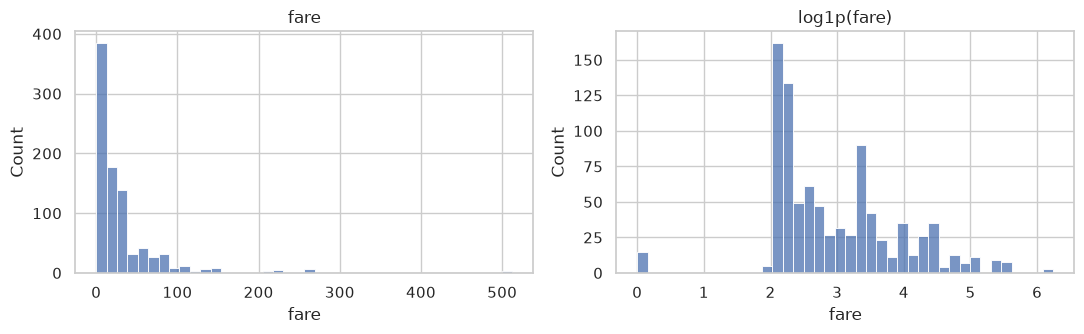

,fare,log1p(fare)
asimetria,4.79,0.39
atipicos IQR,116.00,31.00
tarifas en cero,15.00,NaN


In [24]:
tarifa = pd.read_csv(os.path.join(DATA, "titanic.csv"))["fare"]
log_tarifa = np.log1p(tarifa)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(tarifa, bins=40, ax=axes[0]).set(title="fare")
sns.histplot(log_tarifa, bins=40, ax=axes[1]).set(title="log1p(fare)")
plt.tight_layout()
plt.show()
pd.DataFrame({"fare": [tarifa.skew(), atipicos_iqr(tarifa).sum(), (tarifa == 0).sum()],
              "log1p(fare)": [log_tarifa.skew(), atipicos_iqr(log_tarifa).sum(), np.nan]},
             index=["asimetria", "atipicos IQR", "tarifas en cero"]).round(2)

**✅ Respuesta sugerida:**

La asimetría baja de 4.79 a 0.39 y los atípicos por IQR de 116 a 31. Se usa `log1p` porque hay 15 tarifas en cero y `log(0)` es −∞. Las tarifas altas (hasta 512 libras) corresponden a camarotes de primera clase: son la cola natural de una variable de precios, no errores. Las tarifas en cero sí merecen revisión (pueden ser tripulación o boletos de cortesía).

---
## 5. Ejercicio integrador (20 min).

### 🟢 Ejercicio 7 · Describe la masa corporal en un párrafo.

Con los resultados de los ejercicios 2 a 6, redacta un párrafo de 4 a 6 frases que describa `body_mass_g`: centro y dispersión **por especie** (con las medidas adecuadas a la forma), forma de la distribución, por qué la distribución global engaña y qué atípicos hay. Usa números redondeados y unidades.

**✅ Respuesta sugerida:**

La masa corporal de los pingüinos depende sobre todo de la especie: los Gentoo pesan en promedio unos 5,080 g (desviación estándar ≈ 500 g), mientras que Adelie y Chinstrap rondan los 3,700 g (≈ 460 y 380 g). Dentro de cada especie la distribución es unimodal y casi simétrica, así que media y desviación estándar la describen bien. La distribución global, en cambio, es bimodal porque mezcla grupos: su media (4,200 g) no representa a ninguna especie. Dentro de cada especie solo la regla del IQR señala dos Chinstrap (2,700 y 4,800 g) como atípicos leves; son valores plausibles y se conservan.

---
## ✅ Cierre.

**Hoy vimos:**
* Medidas de centro y dispersión, y cuáles son **robustas** (mediana, IQR, MAD).
* La forma de una distribución: asimetría, curtosis y multimodalidad, y cuatro gráficas para verla.
* Que una distribución global bimodal suele ser la **mezcla de grupos**: hay que describir por especie.
* Tres reglas de valores atípicos y por qué el puntaje *z* clásico sufre **enmascaramiento**.
* La transformación logarítmica para variables con asimetría positiva.

**Práctica (sin calificación, en Classroom):** terminar los ejercicios 🟢 y, si es posible, un reto 🔴.

**Próxima sesión (jue 22 oct):** agregación, relaciones entre variables y visualización efectiva (`04_agregacion_relaciones_visualizacion.ipynb`). Al terminar se publica la **Evaluación semanal 1**.

<p style="text-align: center"><a rel="license" href="http://creativecommons.org/licenses/by/4.0/"><img alt="Licencia Creative Commons" style="border-width:0" src="https://i.creativecommons.org/l/by/4.0/80x15.png" /></a><br />Esta obra está bajo una <a rel="license" href="http://creativecommons.org/licenses/by/4.0/">Licencia Creative Commons Atribución 4.0 Internacional</a>.</p>
<p style="text-align: center">&copy; José Luis Chiquete Valdivieso. 2017-2026.</p>